# 02 · Demand, capacity and price

Before modelling cancellations we need to know what kind of problem this is. Is the hotel usually
half empty, so that the question is *how much* to overbook? Or is demand far above capacity, so
that the question is *whom* to accept? And how much is a room worth on a given night, to whom,
and when do those guests book?

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from src.simulator import load_train, ROOMS
from src.customers import explode_nights
from src import plotting as P

P.setup()
HOTELS = list(ROOMS)
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
df = load_train()

## 1 · Is capacity the constraint?

For every night we count the rooms booked (cancelled bookings included) and the rooms of guests
who actually showed up, and compare them with capacity.

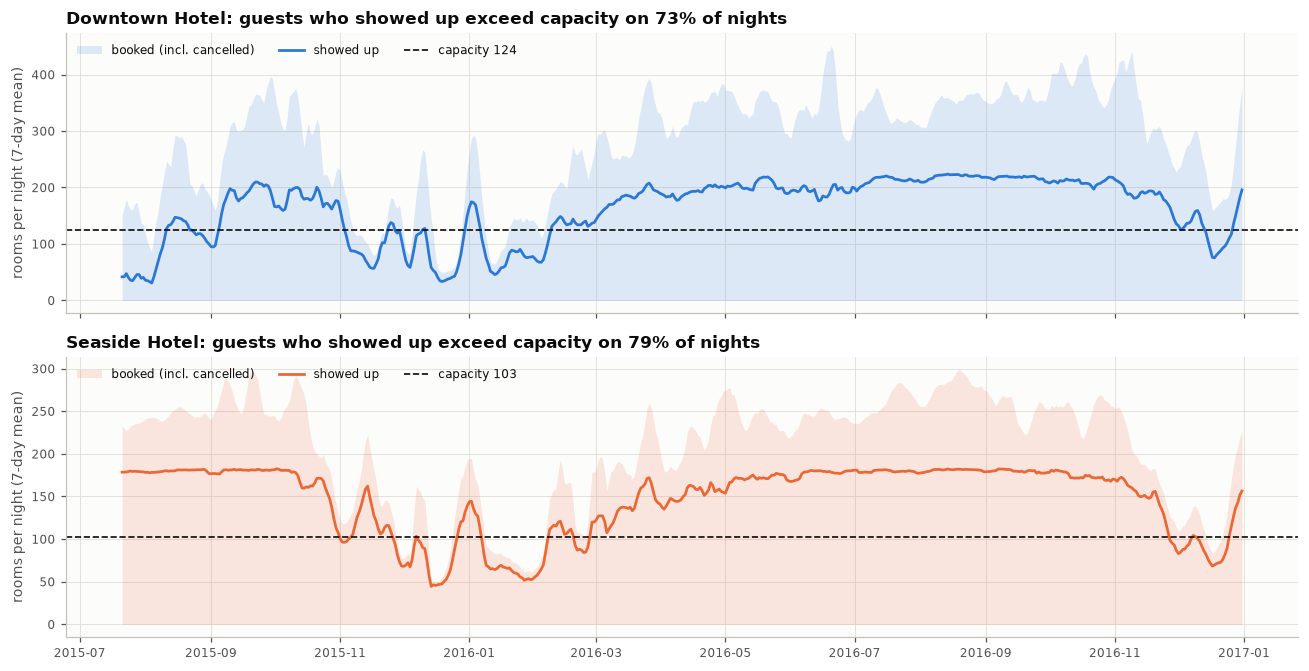

,shown / capacity (mean),nights with shown > capacity,booked / capacity (mean)
hotel,,,
Downtown Hotel,1.30,0.73,2.24
Seaside Hotel,1.43,0.79,2.00


In [2]:
n = explode_nights(df, ["hotel"])
occ = n.groupby(["hotel", "night"]).agg(booked=("show", "size"), shown=("show", "sum")).reset_index()
occ = occ[(occ.night >= "2015-07-15") & (occ.night <= "2016-12-31")]      # earlier stays are truncated
occ["cap"] = occ.hotel.map(ROOMS)

fig, axes = plt.subplots(2, 1, figsize=(12, 6.2), sharex=True)
for ax, h in zip(axes, HOTELS):
    o = occ[occ.hotel == h].set_index("night")
    ax.fill_between(o.index, o.booked.rolling(7).mean(), color=P.HOTEL_COLORS[h], alpha=.15, label="booked (incl. cancelled)")
    ax.plot(o.index, o.shown.rolling(7).mean(), color=P.HOTEL_COLORS[h], lw=1.8, label="showed up")
    ax.axhline(ROOMS[h], color=P.INK, ls="--", lw=1.1, label=f"capacity {ROOMS[h]}")
    ax.set_title(f"{h}: guests who showed up exceed capacity on {(o.shown > ROOMS[h]).mean():.0%} of nights")
    ax.set_ylabel("rooms per night (7-day mean)")
    ax.legend(loc="upper left", ncol=3)
P.save(fig, "demand_vs_capacity")
plt.tight_layout(); plt.show()

occ.groupby("hotel").apply(lambda o: pd.Series({
    "shown / capacity (mean)": (o.shown / o.cap).mean(),
    "nights with shown > capacity": (o.shown > o.cap).mean(),
    "booked / capacity (mean)": (o.booked / o.cap).mean()}), include_groups=False).round(2)

**Demand is far above capacity.** Even counting only guests who showed up, capacity is exceeded
on three nights out of four, by 30–40% on average; counting every booking, demand is more than
twice the rooms. (The flat top of the curves suggests the data comes from larger hotels whose
capacity was scaled down for the challenge.)

The main question is therefore not *how much* to overbook but **whom to accept**: on most nights
there is enough demand to fill the hotel with the best guests and reject the rest. Classic
overbooking (how many extra bookings to take) matters mainly in the low season.

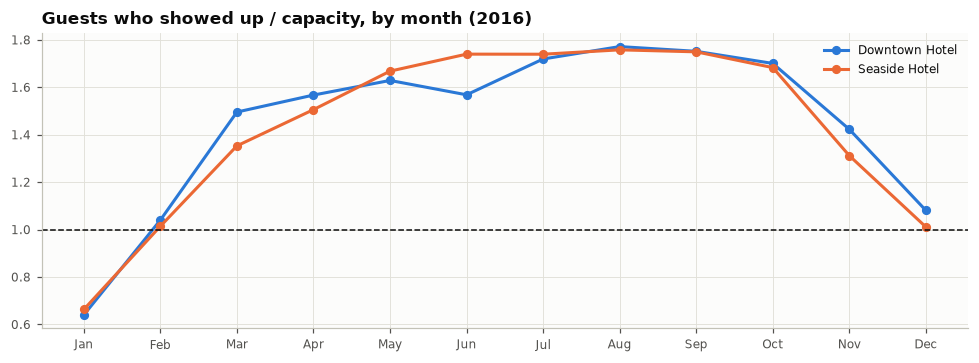

In [3]:
s16 = occ[occ.night.dt.year == 2016]
t = s16.assign(ratio=s16.shown / s16.cap).pivot_table(index=s16.night.dt.month, columns="hotel", values="ratio")
fig, ax = plt.subplots(figsize=(9, 3.4))
for h in HOTELS:
    ax.plot(t.index, t[h], marker="o", color=P.HOTEL_COLORS[h], label=h)
ax.axhline(1, color=P.INK, ls="--", lw=1)
ax.set(title="Guests who showed up / capacity, by month (2016)", xticks=range(1, 13))
ax.set_xticklabels(MONTHS); ax.legend()
plt.tight_layout(); plt.show()

Only January falls clearly below capacity (about 65% at both hotels); February and December sit
around 1.0; from March to November the guests who show up would fill the hotels 1.3–1.8 times.
Overbooking on expected cancellations pays most in the quiet months; in the peak months the
question is entirely *whom* to seat.

## 2 · How much is a room worth, and when?

Capacity is counted in room-nights, so requests must be compared on the **rate per night**, not on
the total value of the stay: a long, cheap stay blocks rooms that could go to several guests who
pay more.

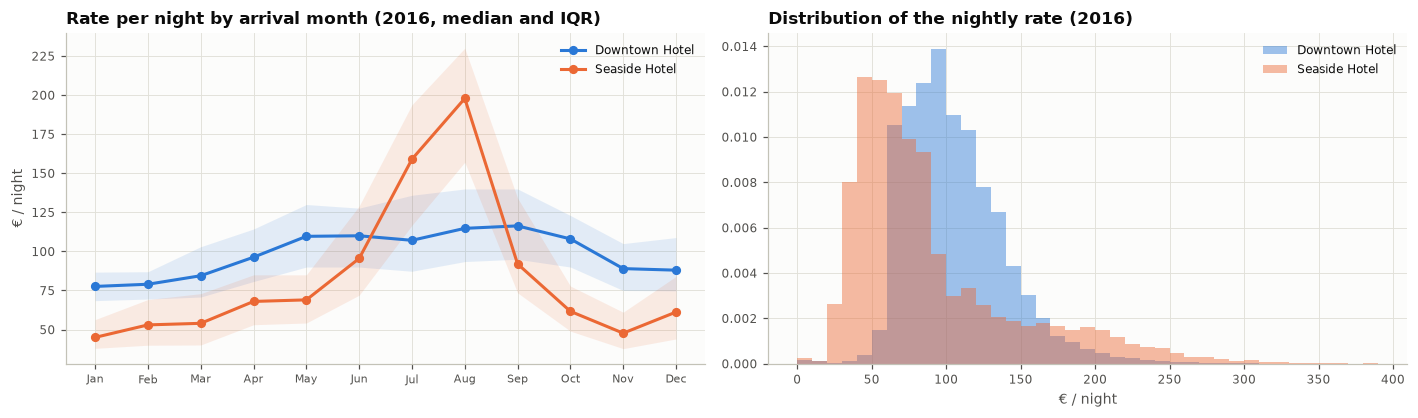

In [4]:
d16 = df[df.arrival_date.dt.year == 2016]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for h in HOTELS:
    g = d16[d16.hotel == h].groupby(d16.arrival_date.dt.month).nightly_rate
    axes[0].plot(g.median().index, g.median(), marker="o", color=P.HOTEL_COLORS[h], label=h)
    axes[0].fill_between(g.median().index, g.quantile(.25), g.quantile(.75), color=P.HOTEL_COLORS[h], alpha=.12)
axes[0].set(title="Rate per night by arrival month (2016, median and IQR)", ylabel="€ / night", xticks=range(1, 13))
axes[0].set_xticklabels(MONTHS, fontsize=7); axes[0].legend()

for h in HOTELS:
    x = d16[(d16.hotel == h) & (d16.nightly_rate > 0)]
    axes[1].hist(x.nightly_rate, bins=np.arange(0, 400, 10), color=P.HOTEL_COLORS[h], alpha=.45, label=h, density=True)
axes[1].set(title="Distribution of the nightly rate (2016)", xlabel="€ / night")
axes[1].legend()
P.save(fig, "rates_by_month")
plt.tight_layout(); plt.show()

**The value of a room-night swings with the season, enormously at Seaside**: about 4× between
winter (~€50) and August (~€200). Downtown moves less (roughly €80–€120). A rule that compares
requests must therefore compare each rate with the *price level of that night*, not with a fixed
threshold.

In [5]:
df["lead_band"] = pd.cut(df.days_ahead, [-1, 7, 30, 90, 180, 1000], labels=["0-7", "8-30", "31-90", "91-180", ">180"])
med = df.groupby(["hotel", df.arrival_date.dt.to_period("M")]).nightly_rate.transform("median")
df["rate_vs_month"] = df.nightly_rate / med
t = df.groupby(["hotel", "lead_band"], observed=True).agg(median_rate=("nightly_rate", "median"),
                                                          rate_vs_month=("rate_vs_month", "median"),
                                                          bookings=("booking_id", "size")).round(2)
t.unstack(0)

median_rate                rate_vs_month                \
hotel     Downtown Hotel Seaside Hotel Downtown Hotel Seaside Hotel   
lead_band                                                             
0-7                97.00         56.00           1.08          0.97   
8-30              100.73         70.00           1.11          1.10   
31-90              96.00         80.09           1.02          1.08   
91-180             96.30         81.82           1.00          0.99   
>180               80.75         72.00           0.84          0.86   

                bookings                
hotel     Downtown Hotel Seaside Hotel  
lead_band                               
0-7                 7712          5858  
8-30                8237          4283  
31-90              13846          6218  
91-180             10302          5411  
>180               11478          4787

Raw rates suggest that last-minute guests pay less at Seaside, but that is seasonal mix: summer
is booked early, winter late. Relative to the median rate of the same hotel and month, guests who
book in the last month pay about the same or slightly more (0.97–1.11×), while those who book more
than six months ahead pay ~15% less. Keeping rooms for late bookers does not mean giving up price.

## 3 · When does demand arrive?

Requests arrive in booking order and must be answered immediately. What matters is how much demand
is **still to come** for a night at the moment we decide.

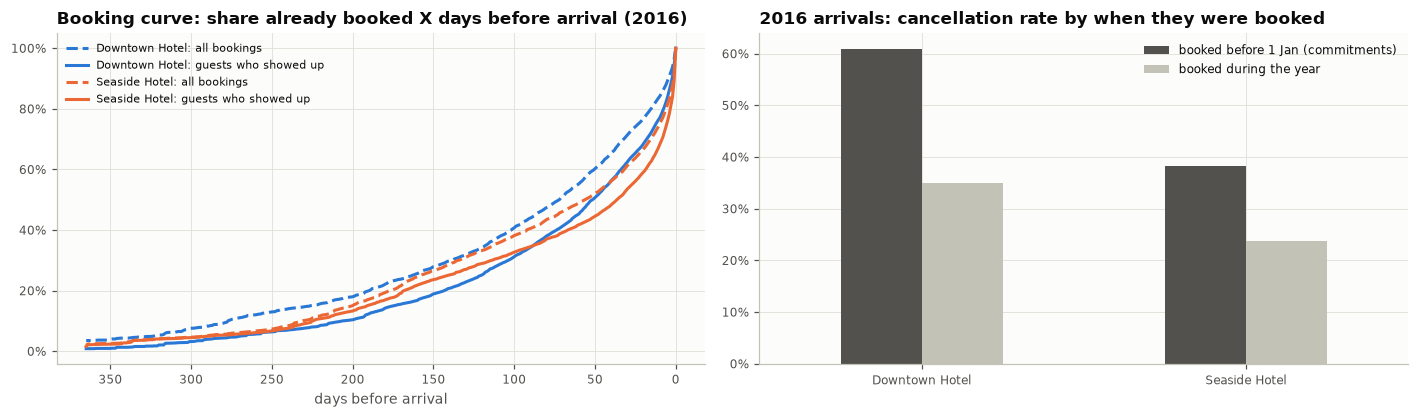

hotel,Downtown Hotel,Seaside Hotel
share of the year's arrivals booked before 1 Jan,0.22,0.21
share of guests who showed up booked in the last 30 days,0.38,0.47
"cancel rate, booked in the last 30 days",0.23,0.12
"cancel rate, booked > 90 days ahead",0.54,0.38


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
grid = np.arange(0, 366)
for h in HOTELS:
    x = d16[d16.hotel == h]
    for subset, ls, lab in ((x, "--", "all bookings"), (x[x.cancelled == 0], "-", "guests who showed up")):
        lead = np.sort(subset.days_ahead.values)
        axes[0].plot(grid, 1 - np.searchsorted(lead, grid) / len(lead), color=P.HOTEL_COLORS[h], ls=ls, label=f"{h}: {lab}")
axes[0].set(title="Booking curve: share already booked X days before arrival (2016)", xlabel="days before arrival")
axes[0].invert_xaxis(); axes[0].yaxis.set_major_formatter(P.PCT); axes[0].legend(fontsize=7)

pre = d16.booking_date < "2016-01-01"
t = d16.groupby(["hotel", pre.map({True: "booked before 1 Jan (commitments)", False: "booked during the year"}).rename("")]).cancelled.mean().unstack()
t.plot.bar(ax=axes[1], color=[P.INK_2, P.LIGHT], rot=0)
axes[1].set(title="2016 arrivals: cancellation rate by when they were booked", xlabel="")
axes[1].yaxis.set_major_formatter(P.PCT)
P.save(fig, "booking_curve")
plt.tight_layout(); plt.show()
shown = d16[d16.cancelled == 0]
pd.DataFrame({"share of the year's arrivals booked before 1 Jan": pre.groupby(d16.hotel).mean(),
              "share of guests who showed up booked in the last 30 days": shown.days_ahead.le(30).groupby(shown.hotel).mean(),
              "cancel rate, booked in the last 30 days": d16[d16.days_ahead <= 30].groupby("hotel").cancelled.mean(),
              "cancel rate, booked > 90 days ahead": d16[d16.days_ahead > 90].groupby("hotel").cancelled.mean()}).T.round(2)

**Late bookers matter most.** About 40% of the guests who show up booked in the last month, and
those bookings rarely cancel; bookings made months ahead cancel far more. About a fifth of the
year's arrivals are already on the books on 1 January (the *commitments* the policy inherits), and
they cancel much more than the bookings made during the year.

Accepting everything that arrives early would fill the hotel with the least reliable guests and
turn away the reliable ones who come later. A good rule needs, for each night, a **price that
reflects the demand still to come**: high when many good guests are still expected, zero when the
night will not fill anyway. That is the *bid price* of notebook 08.

## 4 · Weekly pattern

In [7]:
t = (s16.assign(dow=s16.night.dt.day_of_week, ratio=s16.shown / s16.cap)
        .pivot_table(index="dow", columns="hotel", values="ratio"))
t.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
t.round(2).T

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
hotel,,,,,,,
Downtown Hotel,1.42,1.44,1.44,1.45,1.51,1.54,1.35
Seaside Hotel,1.38,1.43,1.42,1.44,1.47,1.55,1.35


A mild but consistent weekly cycle at both hotels: Saturday is the busiest night and Sunday the
quietest (about ±10% around the mean). The demand forecast of the policy therefore compares each
night with **the same weekday one year earlier**.

## Takeaways

| Finding | Consequence for the system |
|---|---|
| Shows exceed capacity on ~75% of nights | the problem is mostly **whom** to accept |
| Nightly value varies ~4× with the season at Seaside | compare each rate with the price level of *that* night |
| ~40% of shows book in the last month and cancel little | keep rooms for late demand: a per-night **bid price** |
| Commitments cancel much more than in-year bookings | count every booking as its *expected* show, not as one room |
| Weekly cycle (Saturday peak, Sunday low) | forecast each night from the same weekday last year |